In [25]:
from google.colab import drive as dr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [27]:
parent_dr= 'cement/data/'
act_raw= pd.read_csv(parent_dr+'monthly_activity.csv',encoding ='cp949')
act_raw.head()

act = act_raw.melt(id_vars=['year', 'month'], var_name='SOURCE', value_name='ton')
coastal_set = {'HR-OK', 'SP-SC', 'SS-DH'}
act['Region'] = act['SOURCE'].apply(lambda x: 'Coastal area' if x in coastal_set else 'Inland area')

#check1 #share
nir_2022= 43011 #ton
df_2022 = act[act['year'] == 2022]
val_2022_kt = df_2022['ton'].sum() / 1000
print(f"The study coverage: {val_2022_kt:,.2f} kt")
coverage_ratio = (val_2022_kt/nir_2022) *100
print(f"2022 Annual National Total (from activity data): {val_2022_kt:,.2f} kt")
print(f"Coverage compared to NIR 2022: {coverage_ratio:.1f}%")

#check2 #composition
region_sums = df_2022.groupby('Region')['ton'].sum() / 1000
coastal_ratio_of_nir = (region_sums['Coastal area'] / nir_2022) * 100
inland_ratio_of_nir = (region_sums['Inland area'] / nir_2022) * 100
total_coverage_of_nir = coastal_ratio_of_nir + inland_ratio_of_nir
print(f"--- 2022 NIR ({nir_2022} kt) ---")
print(f"Coastal Area: {coastal_ratio_of_nir:.1f}%")
print(f"Inland Area:  {inland_ratio_of_nir:.1f}%")
print(f"Total Analyzed Coverage: {total_coverage_of_nir:.1f}%")

The study coverage: 42,287.08 kt
2022 Annual National Total (from activity data): 42,287.08 kt
Coverage compared to NIR 2022: 98.3%
--- 2022 NIR (43011 kt) ---
Coastal Area: 49.7%
Inland Area:  48.6%
Total Analyzed Coverage: 98.3%


# Statisc  check


In [28]:
# Coastal area
coastal_companies = act[act['Region'] == 'Coastal area']
prod_2018 = coastal_companies[coastal_companies['year'] == 2018]['ton'].sum()
prod_2019 = coastal_companies[coastal_companies['year'] == 2019]['ton'].sum()
change_pct = ((prod_2019 - prod_2018) / prod_2018) * 100
print(f"=== Coastal Area production ===")
print(f"2018 production: {prod_2018:,.2f} ton ({prod_2018/1000:,.2f} kt)")
print(f"2019 production: {prod_2019:,.2f} ton ({prod_2019/1000:,.2f} kt)")
print(f"2019 change rate compared to 2018: {change_pct:+.1f}%")

=== Coastal Area production ===
2018 production: 23,141,135.00 ton (23,141.13 kt)
2019 production: 24,080,765.00 ton (24,080.76 kt)
2019 change rate compared to 2018: +4.1%


In [29]:
ss_yw = act[act['SOURCE'] == 'SS-YW']
base_2018 = ss_yw[ss_yw['year'] == 2018]['ton'].sum()
for year in sorted(ss_yw['year'].unique()):
    val = ss_yw[ss_yw['year'] == year]['ton'].sum()
    diff = val - base_2018
    pct = ((val - base_2018) / base_2018) * 100 if base_2018 > 0 else float('nan')
    marker = " ← base" if year == 2018 else ""
    print(f"{year:<6} {val:>15,.2f} {diff:>+15,.2f} {pct:>+9.1f}%{marker}")

2016      2,881,331.00     +274,097.00     +10.5%
2017      2,738,593.00     +131,359.00      +5.0%
2018      2,607,234.00           +0.00      +0.0% ← base
2019      2,553,952.00      -53,282.00      -2.0%
2020      2,324,253.00     -282,981.00     -10.9%
2021      2,432,942.00     -174,292.00      -6.7%
2022      2,404,711.00     -202,523.00      -7.8%
2023      2,398,038.00     -209,196.00      -8.0%


In [30]:
others = act[act['SOURCE'] != 'SS-YW']
for year in sorted(others['year'].unique()):
    pct_list = []
    for source in others['SOURCE'].unique():
        src_data = others[others['SOURCE'] == source]
        base = src_data[src_data['year'] == 2018]['ton'].sum()
        val = src_data[src_data['year'] == year]['ton'].sum()
        if base > 0:
            pct = ((val - base) / base) * 100
            pct_list.append(pct)

    avg_pct = sum(pct_list) / len(pct_list) if pct_list else float('nan')
    marker = " ← base" if year == 2018 else ""
    print(f"{year:<6} {avg_pct:>+11.1f}%{marker}")

2016         +15.6%
2017          +8.4%
2018          +0.0% ← base
2019          +7.4%
2020          -7.5%
2021          +4.0%
2022          +2.7%
2023          -1.3%


In [31]:
for year in sorted(act['year'].unique()):
    ss_val = act[(act['SOURCE'] == 'SS-YW') & (act['year'] == year)]['ton'].sum()
    total_val = act[act['year'] == year]['ton'].sum()
    ratio = (ss_val / total_val) * 100 if total_val > 0 else float('nan')
    print(f"{year:<6} {ss_val:>15,.2f} {total_val:>15,.2f} {ratio:>+9.1f}%")

2016      2,881,331.00   48,442,984.00      +5.9%
2017      2,738,593.00   47,928,961.00      +5.7%
2018      2,607,234.00   44,645,118.00      +5.8%
2019      2,553,952.00   45,206,281.00      +5.6%
2020      2,324,253.00   41,226,021.00      +5.6%
2021      2,432,942.00   42,795,417.00      +5.7%
2022      2,404,711.00   42,287,083.00      +5.7%
2023      2,398,038.00   41,654,134.00      +5.8%


In [32]:
print("=== annaul plant composition (%) ===")
sources = sorted(act['SOURCE'].unique())
years = sorted(act['year'].unique())
header = f"{'year':<6}" + "".join(f"{s:>10}" for s in sources) + f"{'SS-DH+YW':>12}" + f"{'tot':>10}"
print(header)
print("-" * (6 + 10 * len(sources) + 22))

for year in years:
    total_val = act[act['year'] == year]['ton'].sum()
    row = f"{year:<6}"
    for source in sources:
        val = act[(act['SOURCE'] == source) & (act['year'] == year)]['ton'].sum()
        ratio = (val / total_val) * 100 if total_val > 0 else float('nan')
        row += f"{ratio:>9.1f}%"
    dh_val = act[(act['SOURCE'] == 'SS-DH') & (act['year'] == year)]['ton'].sum()
    yw_val = act[(act['SOURCE'] == 'SS-YW') & (act['year'] == year)]['ton'].sum()
    combined_ratio = ((dh_val + yw_val) / total_val) * 100 if total_val > 0 else float('nan')
    row += f"{combined_ratio:>11.1f}%"
    row += f"{'100.0%':>10}"
    print(row)

=== annaul plant composition (%) ===
year       AS-JC     HH-SG     HH-YW     HL-DY     HR-OK     SP-SC     SS-DH     SS-DY     SS-YW    SS-DH+YW       tot
----------------------------------------------------------------------------------------------------------------------
2016        7.1%      2.4%      7.5%     13.0%     12.0%     16.5%     21.7%     13.8%      5.9%       27.7%    100.0%
2017        7.7%      1.5%      7.4%     13.1%     13.0%     17.5%     21.0%     13.1%      5.7%       26.7%    100.0%
2018        7.0%      1.5%      7.8%     12.5%     12.6%     15.9%     23.3%     13.5%      5.8%       29.2%    100.0%
2019        6.8%      2.4%      7.8%     10.7%     13.0%     17.8%     22.5%     13.5%      5.6%       28.2%    100.0%
2020        7.5%      1.4%      8.1%     11.2%     13.6%     16.6%     22.5%     13.4%      5.6%       28.2%    100.0%
2021        7.4%      2.6%      8.1%     11.2%     12.8%     16.2%     22.5%     13.6%      5.7%       28.2%    100.0%
2022       

# [1] historical emission 2016 ~ 2023

In [33]:
ef = 0.5295; ckkd = 1.02
ef_2030= 0.5138 #2% linear transition since 2025
ef_2050= 0.4352 #12% liner transition since 2025

act['emission'] = act['ton'] * ef * ckkd #tonCO2
act['kt'] = act['emission']/1e3
act['mt'] = act['emission']/1e6
act.head()
code_mapping = {'SP-SC': 'C2', 'SS-DH': 'C1', 'HR-OK': 'C3','SS-DY': 'L1', 'HL-DY': 'L2', 'HH-SG': 'L3','AS-JC':'L4','SS-YW':'L5','HH-YW':'L6'}
act['code'] = act['SOURCE'].map(code_mapping)
act['date'] = pd.to_datetime(act[['year', 'month']].assign(day=1))
act.tail()
act.columns

Index(['year', 'month', 'SOURCE', 'ton', 'Region', 'emission', 'kt', 'mt',
       'code', 'date'],
      dtype='object')

In [34]:
act.head()

,year,month,SOURCE,ton,Region,emission,kt,mt,code,date
0,2016,1,SP-SC,624706.0,Coastal area,337397.46354,337.397464,0.337397,C2,2016-01-01
1,2016,2,SP-SC,455694.0,Coastal area,246115.77246,246.115772,0.246116,C2,2016-02-01
2,2016,3,SP-SC,607757.0,Coastal area,328243.47813,328.243478,0.328243,C2,2016-03-01
3,2016,4,SP-SC,631372.0,Coastal area,340997.70348,340.997703,0.340998,C2,2016-04-01
4,2016,5,SP-SC,670283.0,Coastal area,362013.14547,362.013145,0.362013,C2,2016-05-01


CSV ✅


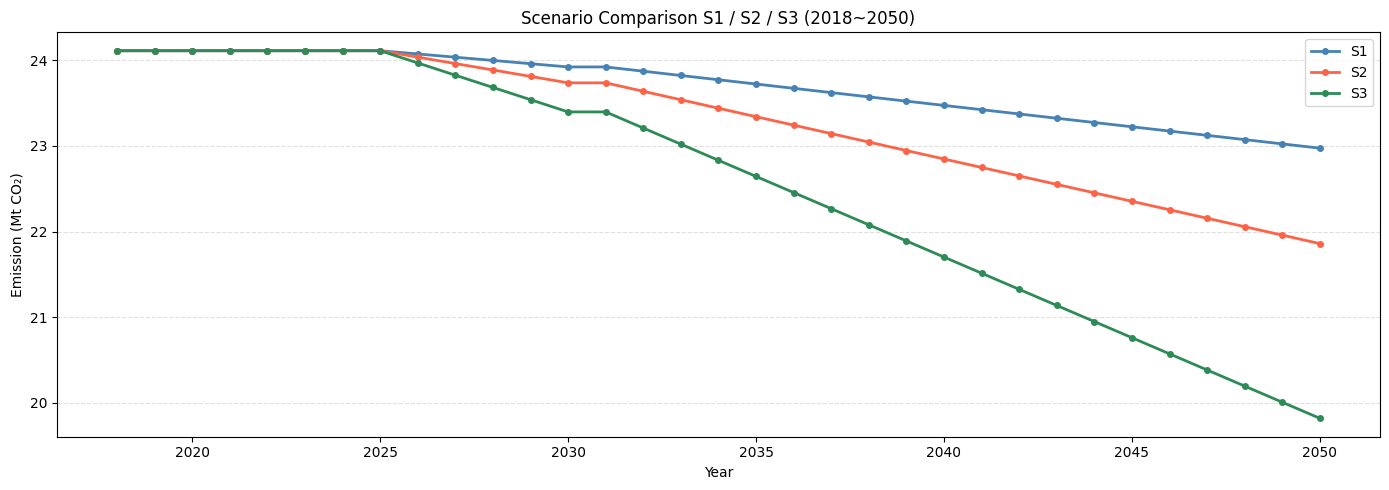

In [35]:
base_ton = (act[act['year'] == 2018].groupby(['Region', 'month'])['ton'].sum())

years          = range(2018, 2051)
regions        = act['Region'].dropna().unique()
months         = range(1, 13)
coastal_months = {3, 4, 5, 9, 10, 11}
#coastal_months = {1, 3, 4, 5, 9, 10, 11}

#emission factor
def get_ef_s1(year):
    if year < 2025:
        return ef
    elif 2025 <= year <= 2030:
        t = (year - 2025) / (2030 - 2025)
        return ef + t * (ef_2030 - ef)
    elif 2031 <= year <= 2050:
        t = (year - 2031) / (2050 - 2031)
        return ef_2030 + t * (ef_2050 - ef_2030)
    else:
        return ef_2050


# create scenario fuction
def build_scenario(target_regions, target_months=None, scenario_name='S'):
    rows = []
    for year in years:
        ef_s1 = get_ef_s1(year)
        for month in months:
            for region in regions:
                ton = base_ton.get((region, month), np.nan)

                month_cond = (target_months is None) or (month in target_months)

                if region in target_regions and month_cond and year >= 2025:
                    ef_used = ef_s1
                else:
                    ef_used = ef

                emission = ton * ef_used * ckkd

                rows.append({
                    'year'    : year,
                    'month'   : month,
                    'region'  : region,
                    'ton'     : ton,
                    'ef_used' : round(ef_used, 6),
                    'emission': emission,
                    'kt'      : emission / 1e3,
                    'mt'      : emission / 1e6,
                    'date'    : pd.Timestamp(year=year, month=month, day=1),
                    'scenario': scenario_name,
                })

    df = pd.DataFrame(rows)
    annual = df.groupby('year')[['emission','kt','mt']].sum().reset_index()
    annual['scenario'] = scenario_name
    return df, annual

# Three scenarios
# S1: Coastal area  + peak seasons
scen1, scen1_annual = build_scenario(
    target_regions={'Coastal area',},
    target_months=coastal_months,
    scenario_name='S1'
)

# S2: Coastal + Inland area + peak seasons
scen2, scen2_annual = build_scenario(
    target_regions={'Coastal area', 'Inland area'},
    target_months=coastal_months,
    scenario_name='S2'
)

# S3: Coastal + Inland area + across month
scen3, scen3_annual = build_scenario(
    target_regions={'Coastal area', 'Inland area'},
    target_months=None,
    scenario_name='S3'
)

# ══════════════════════════════════════════
# 5) concat & CSV
# ══════════════════════════════════════════
scen_all        = pd.concat([scen1, scen2, scen3], ignore_index=True)
scen_annual_all = pd.concat([scen1_annual, scen2_annual, scen3_annual], ignore_index=True)

scen_all.to_csv(parent_dr + 'scenarios_monthly.csv', index=False, encoding='utf-8-sig')
scen_annual_all.to_csv(parent_dr + 'scenarios_annual.csv', index=False, encoding='utf-8-sig')
print("CSV ✅")

# ══════════════════════════════════════════
# 6) plot
# ══════════════════════════════════════════
colors = {'S1': 'steelblue', 'S2': 'tomato', 'S3': 'seagreen'}

fig, ax = plt.subplots(figsize=(14, 5))
for s, grp in scen_annual_all.groupby('scenario'):
    ax.plot(grp['year'], grp['mt'],
            color=colors[s], linewidth=2, marker='o', markersize=4, label=s)

ax.set_xlabel('Year')
ax.set_ylabel('Emission (Mt CO₂)')
ax.set_title('Scenario Comparison S1 / S2 / S3 (2018~2050)')
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# [Scenario1] C1, SS-DH

In [36]:
def get_ef_s1(year):
    if year < 2025:
        return ef
    elif 2025 <= year <= 2030:
        t = (year - 2025) / (2030 - 2025)
        return ef + t * (ef_2030 - ef)
    elif 2031 <= year <= 2050:
        t = (year - 2031) / (2050 - 2031)
        return ef_2030 + t * (ef_2050 - ef_2030)
    else:
        return ef_2050

In [37]:
s1= act.copy()
base_ton = (act[act['year'] == 2018].groupby(['Region', 'month'])['ton'].sum())
print(base_ton.shape)  # (Region * 12)
print(base_ton.head(12))

(24,)
Region        month
Coastal area  1        1621846.0
              2        1699114.0
              3        1880210.0
              4        1735622.0
              5        1883175.0
              6        1941325.0
              7        2047812.0
              8        1872827.0
              9        1964153.0
              10       2179644.0
              11       2191277.0
              12       2124130.0
Name: ton, dtype: float64


In [38]:
#S1 coastal plant
s1= act.copy()
base_ton = (act[act['year'] == 2018].groupby(['Region', 'month'])['ton'].sum())

years  = range(2018, 2051)
regions  = s1['Region'].dropna().unique()
months = range(1, 13)
#coastal_months = {1, 3, 4, 5, 9, 10, 11}
coastal_months = {1,3, 4, 5, 9, 10, 11}
rows = []
for year in years:
    ef_c1 = get_ef_s1(year)
    for month in months:
        for region in regions:
            ton = base_ton.get((region, month), np.nan)
            ef_used = ef_c1 if (region == 'Coastal area' and month in coastal_months and year >= 2025) else ef
            emission = ton * ef_used * ckkd
            rows.append({
                'year'    : year, 'month'   : month,
                'region'  : region, 'ton'     : ton,
                'ef_used' : round(ef_used, 4), 'emission': emission,
                'kt'      : emission / 1e3,'mt'      : emission / 1e6,
                'date'    : pd.Timestamp(year=year, month=month, day=1),})
scen1 = pd.DataFrame(rows)
scen1_annual = scen1.groupby('year')[['emission','kt','mt']].sum().reset_index()
scen1_annual['scenario'] = 'S1'
print(scen1_annual.head())
...

   year      emission            kt         mt scenario
0  2018  2.411238e+07  24112.381781  24.112382       S1
1  2019  2.411238e+07  24112.381781  24.112382       S1
2  2020  2.411238e+07  24112.381781  24.112382       S1
3  2021  2.411238e+07  24112.381781  24.112382       S1
4  2022  2.411238e+07  24112.381781  24.112382       S1


Ellipsis

# Scenario 2

In [39]:
base_ton = (act[act['year'] == 2018].groupby(['Region', 'month'])['ton'].sum())

years          = range(2018, 2051)
regions        = act['Region'].dropna().unique()
months         = range(1, 13)
#target_months ={1,2,6,7,8,12}
#target_months  = {1, 2, 3, 4, 5,6,7,8, 9, 10, 11,12}
target_months = {1, 3, 4, 5, 9, 10, 11}
target_regions = {'Coastal area', 'Inland area'}

rows = []
for year in years:
    ef_s1 = get_ef_s1(year)
    for month in months:
        for region in regions:
            ton = base_ton.get((region, month), np.nan)

            if region in target_regions and month in target_months and year >= 2025:
                ef_used = ef_s1
            else:
                ef_used = ef

            emission = ton * ef_used * ckkd

            rows.append({
                'year'    : year,
                'month'   : month,
                'region'  : region,
                'ton'     : ton,
                'ef_used' : round(ef_used, 6),
                'emission': emission,
                'kt'      : emission / 1e3,
                'mt'      : emission / 1e6,
                'date'    : pd.Timestamp(year=year, month=month, day=1),
            })

scen2 = pd.DataFrame(rows)

scen2_annual = scen2.groupby('year')[['emission','kt','mt']].sum().reset_index()
scen2_annual['scenario'] = 'S2'

print(scen2_annual.head())

   year      emission            kt         mt scenario
0  2018  2.411238e+07  24112.381781  24.112382       S2
1  2019  2.411238e+07  24112.381781  24.112382       S2
2  2020  2.411238e+07  24112.381781  24.112382       S2
3  2021  2.411238e+07  24112.381781  24.112382       S2
4  2022  2.411238e+07  24112.381781  24.112382       S2


# Scenario3

In [40]:
base_ton = (act[act['year'] == 2018].groupby(['Region', 'month'])['ton'].sum())
years          = range(2018, 2051)
regions        = act['Region'].dropna().unique()
months         = range(1, 13)
target_regions = {'Coastal area', 'Inland area'}
rows = []
for year in years:
    ef_s1 = get_ef_s1(year)
    for month in months:
        for region in regions:
            ton = base_ton.get((region, month), np.nan)

            if region in target_regions and year >= 2025:
                ef_used = ef_s1
            else:
                ef_used = ef

            emission = ton * ef_used * ckkd

            rows.append({
                'year'    : year,
                'month'   : month,
                'region'  : region,
                'ton'     : ton,
                'ef_used' : round(ef_used, 6),
                'emission': emission,
                'kt'      : emission / 1e3,
                'mt'      : emission / 1e6,
                'date'    : pd.Timestamp(year=year, month=month, day=1),
            })

scen3 = pd.DataFrame(rows)

scen3_annual = scen3.groupby('year')[['emission','kt','mt']].sum().reset_index()
scen3_annual['scenario'] = 'S3'

print(scen3_annual.head())

   year      emission            kt         mt scenario
0  2018  2.411238e+07  24112.381781  24.112382       S3
1  2019  2.411238e+07  24112.381781  24.112382       S3
2  2020  2.411238e+07  24112.381781  24.112382       S3
3  2021  2.411238e+07  24112.381781  24.112382       S3
4  2022  2.411238e+07  24112.381781  24.112382       S3


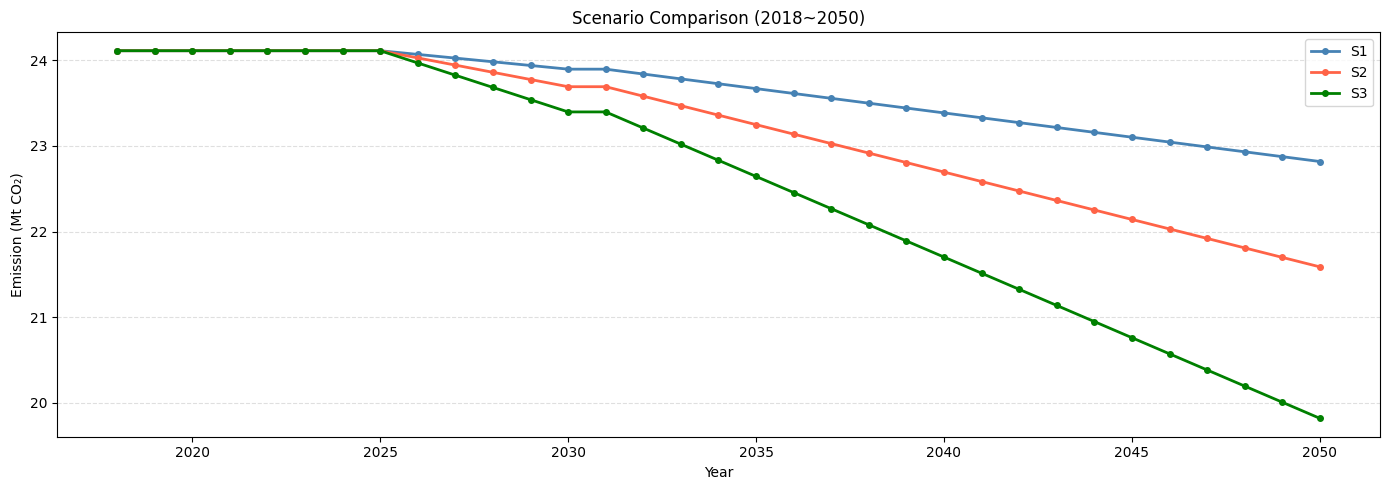

In [41]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(scen1_annual['year'], scen1_annual['mt'],
        color='steelblue', linewidth=2, marker='o', markersize=4, label='S1')
ax.plot(scen2_annual['year'], scen2_annual['mt'],
        color='tomato', linewidth=2, marker='o', markersize=4, label='S2')
ax.plot(scen3_annual['year'], scen3_annual['mt'],
        color='green', linewidth=2, marker='o', markersize=4, label='S3')

ax.set_xlabel('Year')
ax.set_ylabel('Emission (Mt CO₂)')
ax.set_title('Scenario Comparison (2018~2050)')
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [42]:
scen1['scenario'] = 'S1'
scen2['scenario'] = 'S2'
scen3['scenario'] = 'S3'

scen_all = pd.concat([scen1, scen2, scen3], ignore_index=True)

# 저장
scen_all.to_csv(parent_dr+'default_scen.csv', index=False, encoding='cp949')

#print(scen_all.shape)
#print(scen_all['scenario'].value_counts())
print(scen_all.head())
scen_all.columns

   year  month        region        ton  ef_used      emission           kt  \
0  2018      1  Coastal area  1621846.0   0.5295  8.759428e+05   875.942806   
1  2018      1   Inland area  1202732.0   0.5295  6.495835e+05   649.583526   
2  2018      2  Coastal area  1699114.0   0.5295  9.176745e+05   917.674480   
3  2018      2   Inland area  1312752.0   0.5295  7.090042e+05   709.004228   
4  2018      3  Coastal area  1880210.0   0.5295  1.015483e+06  1015.482619   

         mt       date scenario  
0  0.875943 2018-01-01       S1  
1  0.649584 2018-01-01       S1  
2  0.917674 2018-02-01       S1  
3  0.709004 2018-02-01       S1  
4  1.015483 2018-03-01       S1  


Index(['year', 'month', 'region', 'ton', 'ef_used', 'emission', 'kt', 'mt',
       'date', 'scenario'],
      dtype='object')

# Cost of feedstock(USD)

In [43]:
price_raw_rev = pd.read_csv(parent_dr+'GCAM60_NetZero2050_PriceCarbon_REV.csv', encoding='cp949')
price_raw = price_raw_rev.copy()
price_long = price_raw.melt(id_vars='year', var_name='price_scenario', value_name='carbon_price_usd')

# 원하는 4개 시나리오만 이름 정리 (컬럼명은 'price_scenario'로 유지 → scen_all의 'scenario'와 충돌 방지)
scenario_map = {
    'Nationally Determined Contributions (NDCs)': 'NDCs',
    'Below 2°C': 'Below 2°C',
    'Low demand': 'Low demand',
    'Net Zero 2050': 'Net Zero 2050',
}
price_long['price_scenario'] = price_long['price_scenario'].map(scenario_map)
price_long = price_long.dropna(subset=['price_scenario'])

years_full = pd.DataFrame({'year': range(price_long['year'].min(), price_long['year'].max() + 1)})

interp_list = []
for ps in price_long['price_scenario'].unique():
    sub = price_long[price_long['price_scenario'] == ps].sort_values('year')
    merged = years_full.merge(sub[['year', 'carbon_price_usd']], on='year', how='left')
    merged['carbon_price_usd'] = merged['carbon_price_usd'].interpolate(method='linear')
    merged['price_scenario'] = ps
    interp_list.append(merged)

price_long = pd.concat(interp_list, ignore_index=True)
price_long.head(20)


carbon_df = (price_long.merge(pd.DataFrame({'month': range(1, 13)}), how='cross')
    [['price_scenario', 'year', 'month', 'carbon_price_usd']])


conversion_cost = {'cost': -6, 'benefit': 20}

# S1/S2/S3(scen_all) × NDCs/Below2°C/NetZero2050(carbon_df)
scen_all_cost = scen_all.merge(carbon_df, on=['year', 'month'])

# emission cost = emission × carbon price (USD)
scen_all_cost['emission_cost_usd']  = scen_all_cost['emission'] * scen_all_cost['carbon_price_usd']
scen_all_cost['emission_cost_musd'] = scen_all_cost['emission_cost_usd'] / 1e6

# ── 3) cal reduction
base = (scen_all[(scen_all['scenario']=='S1') & (scen_all['year']==2018)]
         [['region','month','emission']].rename(columns={'emission':'base_emission'}))
reduction = scen_all_cost.merge(base, on=['region','month'])
reduction['reduction_t']  = reduction['base_emission'] - reduction['emission']
reduction['reduction_kt'] = reduction['reduction_t'] / 1e3

# ── 4) reduction cost
for case_name, conv_usd in conversion_cost.items():
    reduction[f'conv_usd_{case_name}']  = reduction['reduction_t'] * conv_usd
    reduction[f'conv_musd_{case_name}'] = reduction[f'conv_usd_{case_name}'] / 1e6

final = scen_all_cost.merge(
    reduction[['scenario','price_scenario','year','month','region','reduction_t','reduction_kt',
               'conv_usd_cost','conv_musd_cost','conv_usd_benefit','conv_musd_benefit']],
    on=['scenario','price_scenario','year','month','region'])
final.columns
final.to_csv(parent_dr + 'final_cost.csv', index=False, encoding='cp949')

In [44]:
carbon_df['date'] = pd.to_datetime(dict(year=carbon_df['year'], month=carbon_df['month'], day=1))

for scen in carbon_df['price_scenario'].unique():
    monthly = (carbon_df[carbon_df['price_scenario'] == scen]
               .set_index('date')[['carbon_price_usd']]
               .sort_index())
    annual = (price_long[price_long['price_scenario'] == scen]
              .set_index('year')[['carbon_price_usd']]
              .sort_index())

    check_vals = monthly.resample('YS').mean().round(6)
    ref_vals   = annual.round(6)

    ok = np.isclose(check_vals.values, ref_vals.values, equal_nan=True)
    if not ok.all():
        bad_idx = np.where(~ok.flatten())[0]
        print(f"\n[{scen}] unmatched {len(bad_idx)}건")
        print("year:", ref_vals.index[bad_idx].tolist())
        print("check:", check_vals.values.flatten()[bad_idx])
        print("ref  :", ref_vals.values.flatten()[bad_idx])

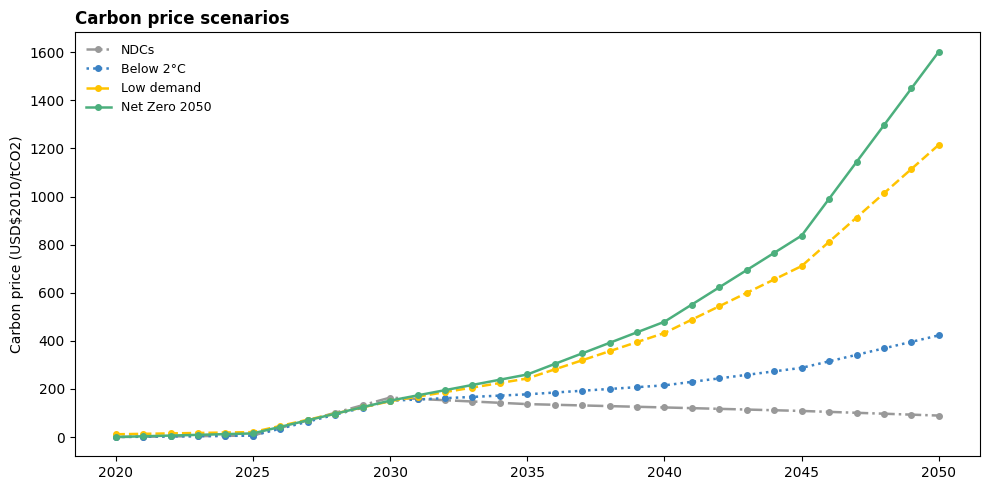

In [45]:
color_map = {
    'NDCs': '#999999',
    'Below 2°C': '#3B82C4',
    'Net Zero 2050': '#4CAF7D',
    'Low demand': '#FFC300' # Added Low demand color
}
style_map = {
    'NDCs': '-.',
    'Below 2°C': ':',
    'Net Zero 2050': '-',
    'Low demand': '--' # Added Low demand linestyle
}
line_label = {
    'NDCs': 'NDCs',
    'Below 2°C': 'Below 2°C',
    'Net Zero 2050': 'Net Zero 2050',
    'Low demand': 'Low demand' # Added Low demand label
}

fig, ax = plt.subplots(figsize=(10, 5))

for ps in ['NDCs', 'Below 2°C', 'Low demand', 'Net Zero 2050']: # Added Low demand to the loop
    sub = price_long[price_long['price_scenario'] == ps].sort_values('year')
    ax.plot(sub['year'], sub['carbon_price_usd'],
            color=color_map[ps], linestyle=style_map[ps], linewidth=1.8,
            label=line_label[ps], marker='o', markersize=4) # Added markers here

ax.set_title('Carbon price scenarios', loc='left', fontsize=12, fontweight='bold')
ax.set_xlabel('')
ax.set_ylabel('Carbon price (USD$2010/tCO2)')
ax.legend(loc='upper left', fontsize=9, frameon=False)
plt.tight_layout()
plt.savefig(parent_dr + 'carbon_price_scenarios.png', dpi=300, bbox_inches='tight')
plt.show()

# CHECK

In [46]:
check = final.groupby(['scenario','year']).agg(
    emission_mt       = ('emission',             lambda x: x.sum()/1e6),
    reduction_kt      = ('reduction_kt',         'sum'),
    emission_cost_bil = ('emission_cost_musd', 'sum'),
    conv_musd_cost    = ('conv_musd_cost',        'sum'),
    conv_musd_benefit = ('conv_musd_benefit',     'sum'),
).reset_index()

# main years
for yr in [2018, 2025, 2030, 2050]:
    print(f"\n{'='*65}")
    print(f"  {yr}yers")
    print(f"{'='*65}")
    print(check[check['year']==yr].to_string(index=False))

# ── Sanity Check
print("\n\n[Sanity Check]")

# 1) 2018 reduction = 0
red_2018 = check[check['year']==2018]['reduction_kt'].values
print(f"\n1) 2018 reduction_kt (should be 0): {red_2018}")

# 2) S3 >= S2 >= S1  reduction order
for yr in [2030, 2050]:
    s1 = check[(check['scenario']=='S1') & (check['year']==yr)]['reduction_kt'].values[0]
    s2 = check[(check['scenario']=='S2') & (check['year']==yr)]['reduction_kt'].values[0]
    s3 = check[(check['scenario']=='S3') & (check['year']==yr)]['reduction_kt'].values[0]
    ok = s3 >= s2 >= s1
    print(f"\n2) {yr} reduction order (S3>=S2>=S1): "
          f"S1={s1:.1f}, S2={s2:.1f}, S3={s3:.1f} kt"
          f" → {'OK' if ok else 'CHECK!'}")

# 3) cost (minus sign), benefit (plus sign)
cost_sign    = check['conv_musd_cost'].sum()
benefit_sign = check['conv_musd_benefit'].sum()
print(f"\n3) cost    (should be <0): {cost_sign:.2f}    → {'OK' if cost_sign    < 0 else 'CHECK!'}")
print(f"   benefit (should be >0): {benefit_sign:.2f} → {'OK' if benefit_sign > 0 else 'CHECK!'}")

# 4) benefit > cost
ratio = abs(benefit_sign / cost_sign)
print(f"\n4) benefit/cost ratio (should be ~{20/6:.2f}): {ratio:.2f}"
      f" → {'OK' if abs(ratio - 20/6) < 0.1 else 'CHECK!'}")


  2018년
Empty DataFrame
Columns: [scenario, year, emission_mt, reduction_kt, emission_cost_bil, conv_musd_cost, conv_musd_benefit]
Index: []

  2025년
scenario  year  emission_mt  reduction_kt  emission_cost_bil  conv_musd_cost  conv_musd_benefit
      S1  2025    96.449527           0.0        1137.877764             0.0                0.0
      S2  2025    96.449527           0.0        1137.877764             0.0                0.0
      S3  2025    96.449527           0.0        1137.877764             0.0                0.0

  2030년
scenario  year  emission_mt  reduction_kt  emission_cost_bil  conv_musd_cost  conv_musd_benefit
      S1  2030    95.587594    861.932860       14688.309953       -5.171597          17.238657
      S2  2030    94.768051   1681.476406       14562.376146      -10.088858          33.629528
      S3  2030    93.589739   2859.787679       14381.312889      -17.158726          57.195754

  2050년
scenario  year  emission_mt  reduction_kt  emission_cost_bil  c